# 02 — Storm surge, GeoClaw method (CLIMADA `TCSurgeGeoClaw`)

**Goal:** run the physical surge model on the same case as notebook 01, measure its cost, and compare it with the bathtub.

GeoClaw solves the shallow-water equations: the storm (wind + low pressure) pushes the sea, and the water propagates
over the sea floor to the coast. It is much more physical than the bathtub, and much heavier.

| | Bathtub (notebook 01) | GeoClaw (this notebook) |
|---|---|---|
| Wind | ECMWF ensemble grid (same as AOS) | parametric wind computed by GeoClaw from the **track** (Holland) |
| Elevation | SRTM 90 m (GigaSpatial) | **GEBCO** (land + sea floor), GigaSpatial has no bathymetry |
| Members | 51 | **1** (control member), then runtime × 51 to estimate the real cost |
| Points | AOS zoom-14 tiles | same AOS tiles |

**Test settings:** Melissa, cycle 2025-10-28 00z, control member, topography resolution **60″ (~2 km, close to the AOS tiles)**.
A first run at 300″ (~10 km, CLIMADA tutorial setting for a laptop) gave unusable results on Jamaica, see the last section.
CLIMADA's default (30″) is meant for an HPC node with ≥ 32 GB / 8 cores.

## 0. Setup

Requirements (once):
- **gfortran** and **make** (macOS: `brew install gcc` and `xcode-select --install`).
- **meson-python, meson, ninja** in the env (Clawpack 5.13 is built with meson): `pip install meson-python meson ninja`.
- **GEBCO grid** (GeoTIFF, bathymetry layer) for a box around Jamaica (N 30, S 5, W −90, E −65) in `data/bathymetry/`.
- Notebook 01 already run: the AOS tiles are read from `data/grid/JAM_z14_tiles.parquet` and the bathtub results from `outputs/`.

First cell, must run before any geospatial import:
- same PROJ fix as notebook 01;
- puts the env's `bin/` first in `PATH`, otherwise the kernel does not find `meson` / `ninja` and the Clawpack build fails.

In [1]:
# Force the PROJ database of this environment (must run before geopandas / rasterio / pyproj)
import os
import sys
from pathlib import Path

proj_dir = str(Path(sys.prefix) / "share" / "proj")
os.environ["PROJ_DATA"] = proj_dir
os.environ["PROJ_LIB"] = proj_dir

import pyproj
pyproj.datadir.set_data_dir(proj_dir)

# Make the tools of this env (meson, ninja, ...) visible to the kernel
env_bin = str(Path(sys.prefix) / "bin")
if env_bin not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = env_bin + os.pathsep + os.environ["PATH"]

print("Python:", sys.executable)
print("PROJ:", proj_dir, "| proj.db found:", (Path(proj_dir) / "proj.db").exists(), "| test:", pyproj.CRS("EPSG:4326").name)

Python: /opt/anaconda3/envs/stormsurge_env/bin/python
PROJ: /opt/anaconda3/envs/stormsurge_env/share/proj | proj.db found: True | test: WGS 84


In [2]:
import time
import shutil
import subprocess

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CONFIG = {
    "storm_name": "MELISSA",
    "country_iso3": "JAM",
    "cycle_tag": "melissa_20251028_00z",          # same tag as notebook 01 outputs
    "bufr_file": PROJECT / "data/bufr/20251028_00z_tf.bufr",
    "grid_file": PROJECT / "data/grid/JAM_z14_tiles.parquet",
    "bathymetry_dir": PROJECT / "data/bathymetry",
    "output_dir": PROJECT / "outputs",
    "track_time_step_h": 1,
    "topo_res_as": 60,           # arc-seconds (~2 km). 300 (~10 km) is too coarse for Jamaica; 30 = CLIMADA default (HPC)
    "suspect_surge_m": 20,       # values above this are not surge (see section 5)
    "surge_thresholds_m": [0.5, 1.0, 2.0, 3.0],
    "n_members_aos": 51,
}

TIMINGS = {}

class timer:
    # Usage: `with timer("step name"):` -> stores runtime in TIMINGS
    def __init__(self, name): self.name = name
    def __enter__(self): self.t0 = time.perf_counter()
    def __exit__(self, *exc):
        TIMINGS[self.name] = time.perf_counter() - self.t0
        print(f"[{self.name}] {TIMINGS[self.name]:.1f} s")

# Tool checks
for tool in ("gfortran", "make", "git", "meson", "ninja"):
    path = shutil.which(tool)
    print(f"{tool:9s}: {path or 'NOT FOUND'}")
print(subprocess.run(["gfortran", "--version"], capture_output=True, text=True).stdout.splitlines()[0])

gfortran : /opt/homebrew/bin/gfortran
make     : /usr/bin/make
git      : /usr/bin/git
meson    : /opt/anaconda3/envs/stormsurge_env/bin/meson
ninja    : /opt/anaconda3/envs/stormsurge_env/bin/ninja
GNU Fortran (Homebrew GCC 16.2.0) 16.2.0


## 1. GEBCO topography + bathymetry

In [3]:
gebco_files = sorted(CONFIG["bathymetry_dir"].glob("*.tif"))
assert gebco_files, f"No GEBCO GeoTIFF found in {CONFIG['bathymetry_dir']}"
CONFIG["topo_file"] = gebco_files[0]

with rasterio.open(CONFIG["topo_file"]) as src:
    print("File:", CONFIG["topo_file"].name)
    print("Bounds:", [round(v, 2) for v in src.bounds], "| res (arc-sec):", round(src.res[0] * 3600, 1),
          "| CRS:", src.crs, "| size:", src.width, "x", src.height)
    sample = src.read(1, out_shape=(1, src.height // 20, src.width // 20))
    print(f"Elevation range (subsampled): {sample.min()} to {sample.max()} m (negative = sea floor)")

File: gebco_2026_n30.0_s5.0_w-90.0_e-65.0_geotiff.tif
Bounds: [-90.0, 5.0, -65.0, 30.0] | res (arc-sec): 15.0 | CRS: EPSG:4326 | size: 6000 x 6000
Elevation range (subsampled): -8496 to 4817 m (negative = sea floor)


## 2. AOS tiles + distance to coast

Same tiles as notebook 01. GeoClaw also needs the distance to coast to select coastal points, and CLIMADA would again
try the blocked NASA file, so we reuse the notebook-01 approach (distance to the GigaSpatial country boundary).

In [4]:
from gigaspatial.handlers import AdminBoundaries
from climada.hazard import Centroids

tiles = gpd.read_parquet(CONFIG["grid_file"])
centres = tiles.geometry.to_crs("EPSG:3857").centroid.to_crs("EPSG:4326")
tiles["lon"] = centres.x.values
tiles["lat"] = centres.y.values

with timer("2_dist_coast"):
    country = gpd.GeoSeries(
        [AdminBoundaries.create(country_code=CONFIG["country_iso3"]).to_geoms()[0]], crs="EPSG:4326")
    utm = country.estimate_utm_crs()
    country_m = country.to_crs(utm).iloc[0]
    pts_m = gpd.GeoSeries(gpd.points_from_xy(tiles["lon"], tiles["lat"]), crs="EPSG:4326").to_crs(utm)
    dist_m = pts_m.distance(country_m.boundary).values
    tiles["dist_coast_m"] = np.where(pts_m.within(country_m).values, -dist_m, dist_m)

centroids = Centroids(lat=tiles["lat"].values, lon=tiles["lon"].values)
_dist = tiles["dist_coast_m"].values
centroids.get_dist_coast = lambda signed=False, precomputed=True: _dist if signed else np.abs(_dist)
print(f"{len(tiles)} AOS tiles")

INFO        AdminBoundaries 2026-10-10 13:27:59,733       : AdminBoundaries.create country=JAM level=0 data_store=False path=False
WARNING     AdminBoundaries 2026-10-10 13:27:59,735       : GeoRepo check failed: API Key is required. Provide it as a parameter or set GEOREPO_API_KEY environment variable.
INFO        AdminBoundaries 2026-10-10 13:27:59,735       : Attempting GADM fallback.
INFO        AdminBoundaries 2026-10-10 13:27:59,735       : Loading GADM data for JAM admin_level=0 from https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_JAM_0.json
INFO        EntityManager 2026-10-10 13:28:01,454       : Validating AdminBoundary entities:   0%|          | 0/1 [00:00<?, ?it/s]
INFO        EntityManager 2026-10-10 13:28:01,457       : Validating AdminBoundary entities: 100%|##########| 1/1 [00:00<00:00, 2462.89it/s]
INFO        EntityManager 2026-10-10 13:28:01,457       : 


[2_dist_coast] 1.8 s
2234 AOS tiles


## 3. Track — control member of the ECMWF ensemble

The BUFR file has the 51 ensemble members (+ possibly the deterministic HRES run). We keep the **control** member
(ensemble run, member number not in 1–50). GeoClaw estimates missing storm radii itself.

**Unit fix:** the BUFR tracks store the wind in **m/s**, but CLIMADA's GeoClaw code assumes **knots** and converts again,
so without this fix GeoClaw sees about half the real wind. We convert the track to knots before the run.

In [5]:
from climada.hazard import TCTracks
from climada_petals.hazard.tc_tracks_forecast import TCForecast

fc = TCForecast()
fc.read_one_bufr_tc(str(CONFIG["bufr_file"]))
storm_tracks = [t for t in fc.data if t.name.upper() == CONFIG["storm_name"]]

members_info = pd.DataFrame({
    "idx": range(len(storm_tracks)),
    "ensemble_number": [int(t.attrs["ensemble_number"]) for t in storm_tracks],
    "is_ensemble": [bool(t.attrs["is_ensemble"]) for t in storm_tracks],
    "max_wind_kt": [float(t.max_sustained_wind.max()) for t in storm_tracks],
    "min_pressure_hpa": [float(t.central_pressure.min()) for t in storm_tracks],
})
print(f"{len(storm_tracks)} {CONFIG['storm_name']} tracks")
print("Non-perturbed candidates (control / HRES):")
print(members_info[~members_info["ensemble_number"].between(1, 50) | ~members_info["is_ensemble"]].to_string(index=False))

control = members_info[members_info["is_ensemble"] & ~members_info["ensemble_number"].between(1, 50)]
assert len(control) == 1, "Control member not found unambiguously, check the table above"
track = storm_tracks[int(control["idx"].iloc[0])]
CONFIG["member_label"] = f"control (ensemble_number={int(control['ensemble_number'].iloc[0])})"

# BUFR wind is in m/s, CLIMADA's GeoClaw code assumes knots: convert
assert track.attrs.get("max_sustained_wind_unit") == "m/s", track.attrs.get("max_sustained_wind_unit")
track["max_sustained_wind"] = track["max_sustained_wind"] / 0.514444
track.attrs["max_sustained_wind_unit"] = "kn"
print(f"Control track: max wind {float(track.max_sustained_wind.max()):.0f} kt | min pressure {float(track.central_pressure.min()):.0f} hPa")

track.attrs["name"] = f"{CONFIG['storm_name']}_control"
track.attrs["sid"] = f"{CONFIG['storm_name']}_control"
tracks = TCTracks(data=[track])
tracks.equal_timestep(time_step_h=CONFIG["track_time_step_h"])
print("Selected:", CONFIG["member_label"], "| time steps:", tracks.data[0].time.size)

52 MELISSA tracks
Non-perturbed candidates (control / HRES):
 idx  ensemble_number  is_ensemble  max_wind_kt  min_pressure_hpa
  50               51         True         44.8             951.0
  51               52        False         44.8             951.0
Control track: max wind 87 kt | min pressure 951 hPa
Selected: control (ensemble_number=51) | time steps: 169


## 4. Install GeoClaw (first run only)

CLIMADA downloads Clawpack (v5.13.1) from GitHub and installs it with pip; the Fortran solver is compiled at the
first simulation. This can take several minutes and is timed separately from the simulation.

In [6]:
from climada_petals.hazard.tc_surge_geoclaw.setup_clawpack import setup_clawpack

with timer("4_setup_clawpack"):
    setup_clawpack()

[4_setup_clawpack] 0.1 s


## 5. GeoClaw simulation — 1 member

Runs the shallow-water solver for each landfall event of the track, on the AOS tiles within 50 km inland / 10 km offshore.
Run files (and plots of the simulated areas, useful for debugging) are written under `~/climada/data/geoclaw/runs`.

**Sanity check:** GeoClaw returns the maximum **water depth** in the solver cell that contains each point. If the cell is
at sea (coarse resolution on a steep coast), that value is the sea depth, not a surge. Values above
`suspect_surge_m` (20 m) are flagged and excluded from the comparison.

This step can take long at 60″ (estimated tens of minutes on a laptop). Let it run; the runtime is the result we need.

/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730:

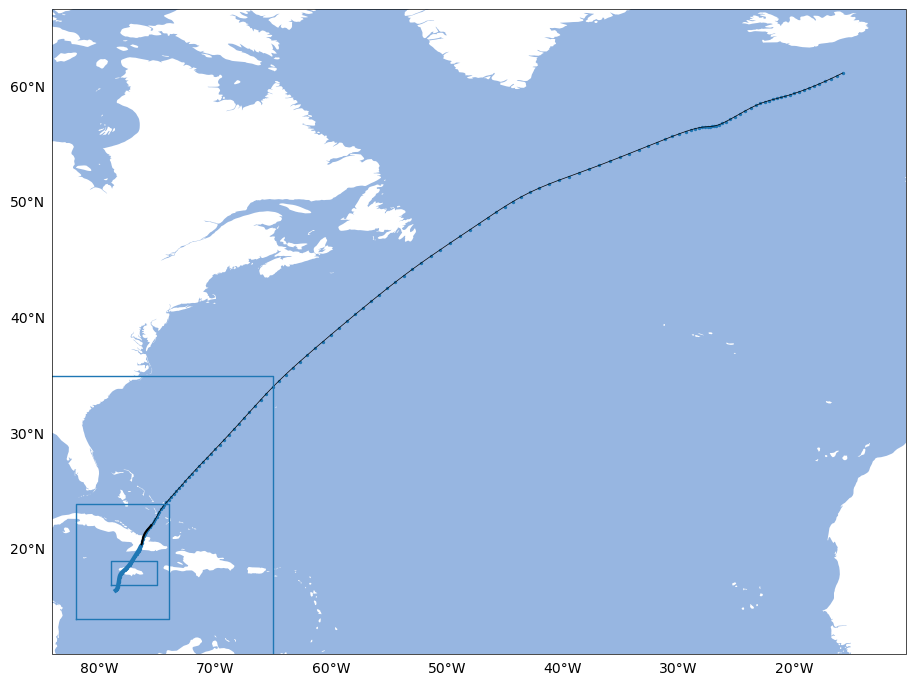

/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


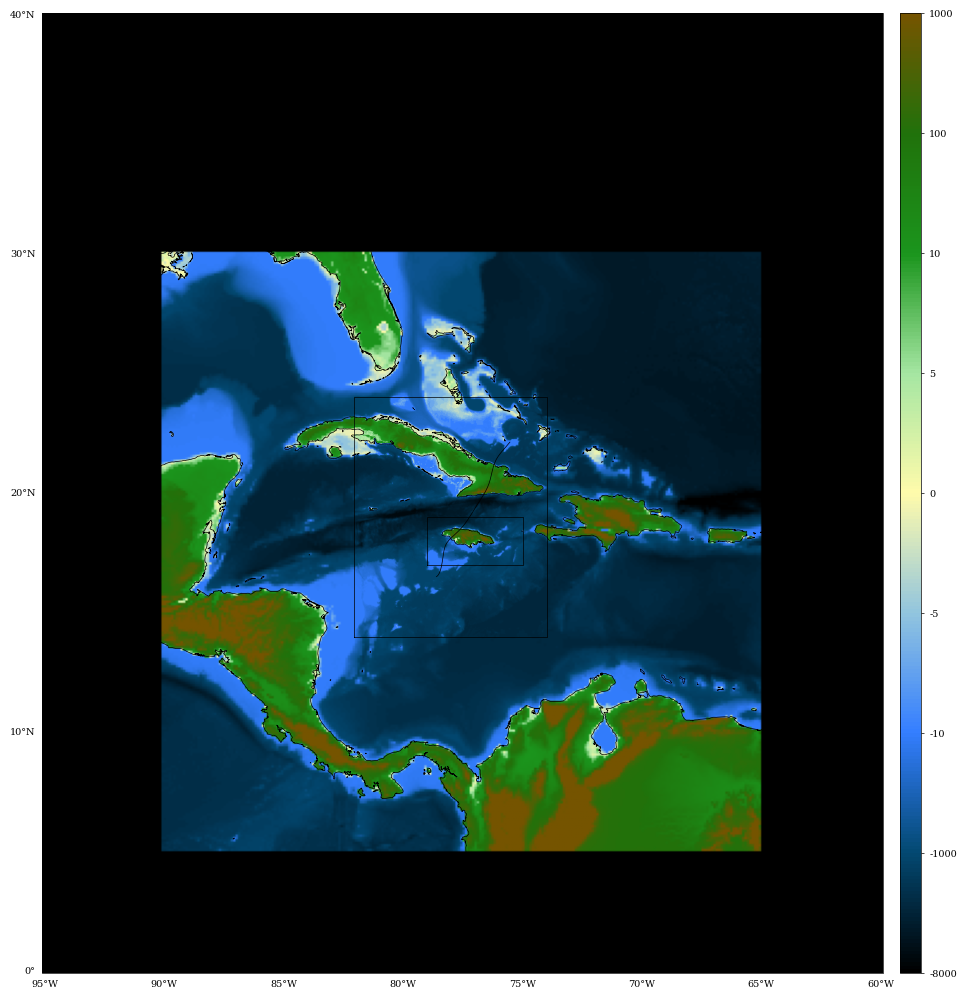

/opt/anaconda3/envs/stormsurge_env/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


[5_geoclaw_1_member] 908.2 s
Raw: tiles > 0: 89 | max: 131.26 m
Suspect tiles (> 20 m, sea depth not surge): 10
Kept: tiles > 0: 79 | max: 14.26 m


In [7]:
from climada_petals.hazard.tc_surge_geoclaw import TCSurgeGeoClaw

with timer("5_geoclaw_1_member"):
    surge_haz = TCSurgeGeoClaw.from_tc_tracks(
        tracks,
        centroids,
        str(CONFIG["topo_file"]),
        geoclaw_kwargs={"topo_res_as": CONFIG["topo_res_as"]},
    )

surge_gc_raw = surge_haz.intensity.toarray()[0]   # (tiles,), metres
suspect = surge_gc_raw > CONFIG["suspect_surge_m"]
surge_gc = np.where(suspect, 0.0, surge_gc_raw)
print(f"Raw: tiles > 0: {(surge_gc_raw > 0).sum()} | max: {surge_gc_raw.max():.2f} m")
print(f"Suspect tiles (> {CONFIG['suspect_surge_m']} m, sea depth not surge): {suspect.sum()}")
print(f"Kept: tiles > 0: {(surge_gc > 0).sum()} | max: {surge_gc.max():.2f} m")

## 6. Comparison with the bathtub — same member (control)

The bathtub results of notebook 01 use the ECMWF GRIB member numbers, where the control is member **0**.

In [8]:
by_member = pd.read_parquet(CONFIG["output_dir"] / f"{CONFIG['cycle_tag']}_surge_by_member.parquet")
bt_control = by_member[by_member["member"] == 0].set_index("tile_id")["surge_m"]

comp = tiles[["tile_id", "lon", "lat", "geometry"]].copy()
comp["geoclaw_m"] = surge_gc
comp["geoclaw_raw_m"] = surge_gc_raw
comp["geoclaw_suspect"] = suspect
comp["bathtub_m"] = comp["tile_id"].map(bt_control).fillna(0.0).values

rows = []
for thr in [0.0] + CONFIG["surge_thresholds_m"]:
    rows.append({
        "threshold": f"> {thr:g} m" if thr == 0 else f">= {thr:g} m",
        "bathtub_tiles": int(((comp["bathtub_m"] > 0) if thr == 0 else (comp["bathtub_m"] >= thr)).sum()),
        "geoclaw_tiles": int(((comp["geoclaw_m"] > 0) if thr == 0 else (comp["geoclaw_m"] >= thr)).sum()),
    })
table = pd.DataFrame(rows)
print(f"Max surge — bathtub: {comp['bathtub_m'].max():.2f} m | GeoClaw: {comp['geoclaw_m'].max():.2f} m")
both = comp[(comp["bathtub_m"] > 0) & (comp["geoclaw_m"] > 0)]
print(f"Tiles with surge in both: {len(both)}")
table

Max surge — bathtub: 1.30 m | GeoClaw: 14.26 m
Tiles with surge in both: 5


,threshold,bathtub_tiles,geoclaw_tiles
0,> 0 m,7,79
1,>= 0.5 m,6,70
2,>= 1 m,1,64
3,>= 2 m,0,55
4,>= 3 m,0,44


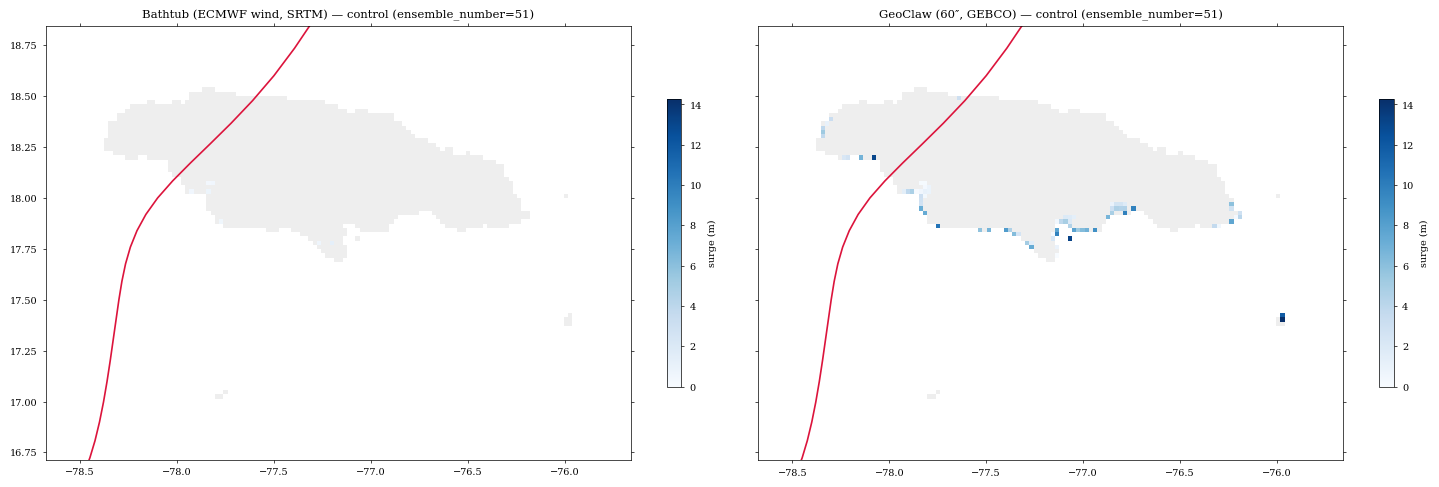

In [9]:
lon_min, lat_min, lon_max, lat_max = tiles.total_bounds
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
vmax = max(comp["bathtub_m"].max(), comp["geoclaw_m"].max(), 0.1)
for ax, col, title in [(axes[0], "bathtub_m", "Bathtub (ECMWF wind, SRTM)"),
                       (axes[1], "geoclaw_m", f"GeoClaw ({CONFIG['topo_res_as']}″, GEBCO)")]:
    tiles.plot(ax=ax, color="#eeeeee", edgecolor="none")
    hit = comp[comp[col] > 0]
    if len(hit):
        hit.plot(ax=ax, column=col, cmap="Blues", vmin=0, vmax=vmax, legend=True,
                 legend_kwds={"label": "surge (m)", "shrink": 0.6})
    ax.plot(tracks.data[0].lon, tracks.data[0].lat, color="crimson", linewidth=1.2)
    ax.set_xlim(lon_min - 0.3, lon_max + 0.3)
    ax.set_ylim(lat_min - 0.3, lat_max + 0.3)
    ax.set_title(f"{title} — {CONFIG['member_label']}")
plt.tight_layout()
plt.savefig(CONFIG["output_dir"] / f"{CONFIG['cycle_tag']}_bathtub_vs_geoclaw_control_{CONFIG['topo_res_as']}as.png", dpi=150)
plt.show()

## 7. Save outputs + runtime

In [10]:
comp.drop(columns="geometry").to_parquet(
    CONFIG["output_dir"] / f"{CONFIG['cycle_tag']}_geoclaw_vs_bathtub_control_{CONFIG['topo_res_as']}as.parquet", index=False)

timings = pd.Series(TIMINGS, name="seconds").round(1)
print(timings.to_string())

t_member = TIMINGS["5_geoclaw_1_member"]
t_51 = t_member * CONFIG["n_members_aos"]
print(f"\nGeoClaw, 1 member at {CONFIG['topo_res_as']}″: {t_member / 60:.1f} min")
print(f"Estimated 51 members, 1 storm (sequential, this machine): {t_51 / 3600:.1f} h")
print("Bathtub, 51 members (notebook 01): 0.3 s surge + ~30 s wind reading")
timings.to_csv(CONFIG["output_dir"] / f"{CONFIG['cycle_tag']}_geoclaw_timings_{CONFIG['topo_res_as']}as.csv")

2_dist_coast            1.8
4_setup_clawpack        0.1
5_geoclaw_1_member    908.2

GeoClaw, 1 member at 60″: 15.1 min
Estimated 51 members, 1 storm (sequential, this machine): 12.9 h
Bathtub, 51 members (notebook 01): 0.3 s surge + ~30 s wind reading
